# Storytelling charts – message titles

**Video 8.5** · ShopKart project

**Goal:** Make the three charts for the ShopKart findings deck. Each chart has a message title that states the finding, uses grey for context and one colour for the point.

**How to open in Colab:** go to colab.research.google.com → File → Upload notebook → choose this file. Then click the folder icon on the left and drag these data files in: `shopkart_clean.csv`. Then run cells from top to bottom (Shift + Enter).

Used for the 3-slide example findings deck in Video 8.5.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
df = pd.read_csv("shopkart_clean.csv")
os.makedirs("images", exist_ok=True)
MAIN, HIGHLIGHT, GREY = "#2a78d6", "#eb6834", "#b8b6ae"
df["is_returned"] = (df["returned"] == "Y").astype(int)   # 1 = returned, 0 = kept

## Finding 1 – Pune's return rate

In [2]:
overall = df["is_returned"].mean() * 100
by_city = (df.groupby("city")["is_returned"].mean() * 100).sort_values(ascending=False)
ratio = by_city["Pune"] / overall
pune = df[df["city"] == "Pune"]
print(f"Overall return rate : {overall:.1f}%")
print(f"Pune return rate    : {by_city['Pune']:.1f}%  ({pune['is_returned'].sum()} of {len(pune)} orders)")
print(f"Ratio               : {ratio:.2f}x")
print(f"Next highest city   : {by_city.index[1]} {by_city.iloc[1]:.1f}%")
print(f"Revenue of returned Pune orders: ₹{pune.loc[pune['is_returned'] == 1, 'revenue'].sum():,.0f}")

Overall return rate : 13.7%
Pune return rate    : 32.4%  (146 of 451 orders)
Ratio               : 2.36x
Next highest city   : Kolkata 14.3%
Revenue of returned Pune orders: ₹536,752


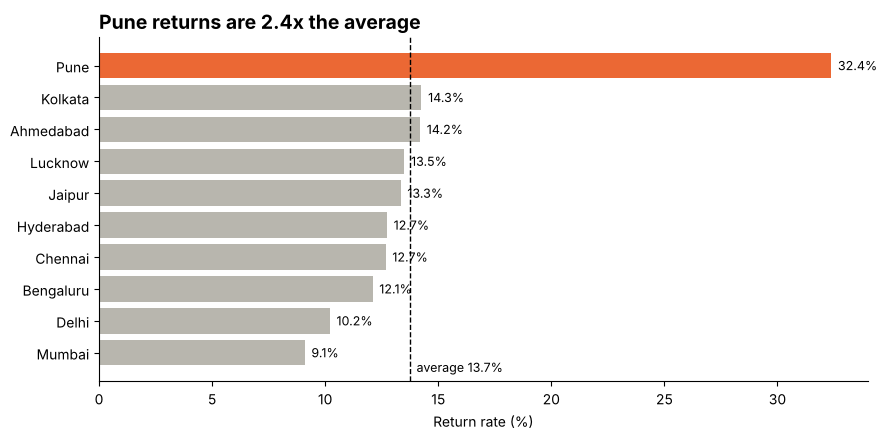

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
s = by_city.sort_values()
ax.barh(s.index, s.values, color=[HIGHLIGHT if c == "Pune" else GREY for c in s.index])
ax.axvline(overall, color="black", linestyle="--", linewidth=1)
ax.text(overall + 0.3, -0.6, f"average {overall:.1f}%", fontsize=9)
for i, v in enumerate(s.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title(f"Pune returns are {ratio:.1f}x the average", loc="left", fontsize=14, weight="bold")
ax.set_xlabel("Return rate (%)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/M08_story1_pune_returns.png", dpi=150)
plt.show()

## Finding 2 – Is it just slow delivery?
Pune deliveries are slower. But even at the SAME delivery speed, Pune returns more – so slow delivery is only part of the story.

In [4]:
df["delivery_band"] = pd.cut(df["delivery_days"], bins=[0, 4, 5, 7, 20], labels=["2-4 days", "5 days", "6-7 days", "8+ days"])
df["area"] = df["city"].where(df["city"] == "Pune", "Other cities")
band = (df.pivot_table(index="delivery_band", columns="area", values="is_returned", aggfunc="mean", observed=True) * 100).round(1)
print(band)
print()
print("Average delivery days:")
print(df.groupby("area")["delivery_days"].mean().round(2))

area           Other cities  Pune
delivery_band                    
2-4 days               10.5  31.7
5 days                 14.8  25.9
6-7 days               14.1  33.8
8+ days                19.7  48.8

Average delivery days:
area
Other cities    3.99
Pune            5.77
Name: delivery_days, dtype: float64


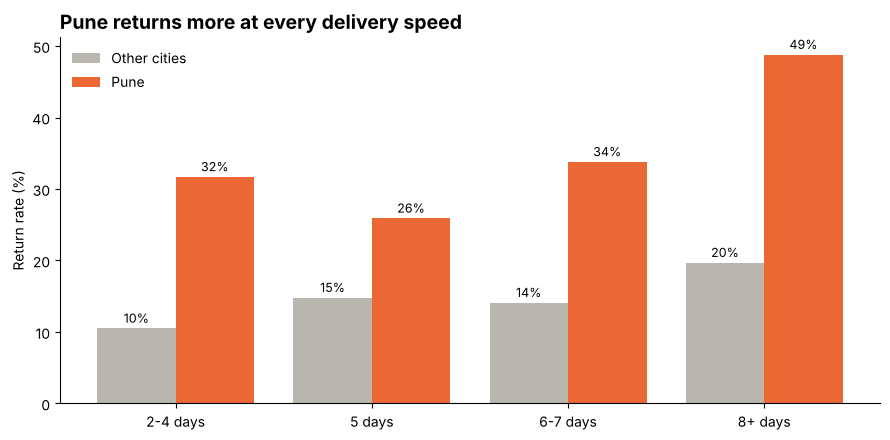

In [5]:
import numpy as np
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(band))
ax.bar(x - 0.2, band["Other cities"], width=0.4, color=GREY, label="Other cities")
ax.bar(x + 0.2, band["Pune"], width=0.4, color=HIGHLIGHT, label="Pune")
for i in range(len(band)):
    ax.text(i - 0.2, band["Other cities"].iloc[i] + 0.8, f"{band['Other cities'].iloc[i]:.0f}%", ha="center", fontsize=9)
    ax.text(i + 0.2, band["Pune"].iloc[i] + 0.8, f"{band['Pune'].iloc[i]:.0f}%", ha="center", fontsize=9)
ax.set_xticks(x, band.index)
ax.set_ylabel("Return rate (%)")
ax.set_title("Pune returns more at every delivery speed", loc="left", fontsize=14, weight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/M08_story2_pune_by_delivery.png", dpi=150)
plt.show()

## Finding 3 – Which category to look at first?

In [6]:
cat = (df.groupby("category")["is_returned"].mean() * 100)
pune_cat = (pune.groupby("category")["returned"].apply(lambda s: (s == "Y").mean()) * 100)
print("All cities:"); print(cat.round(1).sort_values(ascending=False))
print("\nPune only:"); print(pune_cat.round(1).sort_values(ascending=False))

All cities:
category
Fashion        21.0
Electronics    13.5
Home           12.5
Beauty          9.5
Books           7.3
Name: is_returned, dtype: float64

Pune only:
category
Fashion        38.8
Electronics    33.7
Home           31.7
Beauty         26.5
Books          20.7
Name: returned, dtype: float64


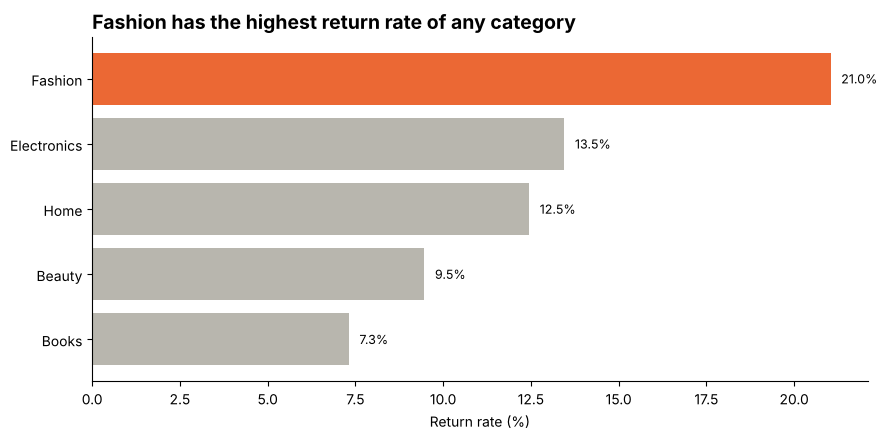

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
s = cat.sort_values()
ax.barh(s.index, s.values, color=[HIGHLIGHT if c == "Fashion" else GREY for c in s.index])
for i, v in enumerate(s.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_title("Fashion has the highest return rate of any category", loc="left", fontsize=14, weight="bold")
ax.set_xlabel("Return rate (%)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/M08_story3_fashion_returns.png", dpi=150)
plt.show()